In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
focal_length = 800
baseline = 0.2
disparities = [80, 40, 20]

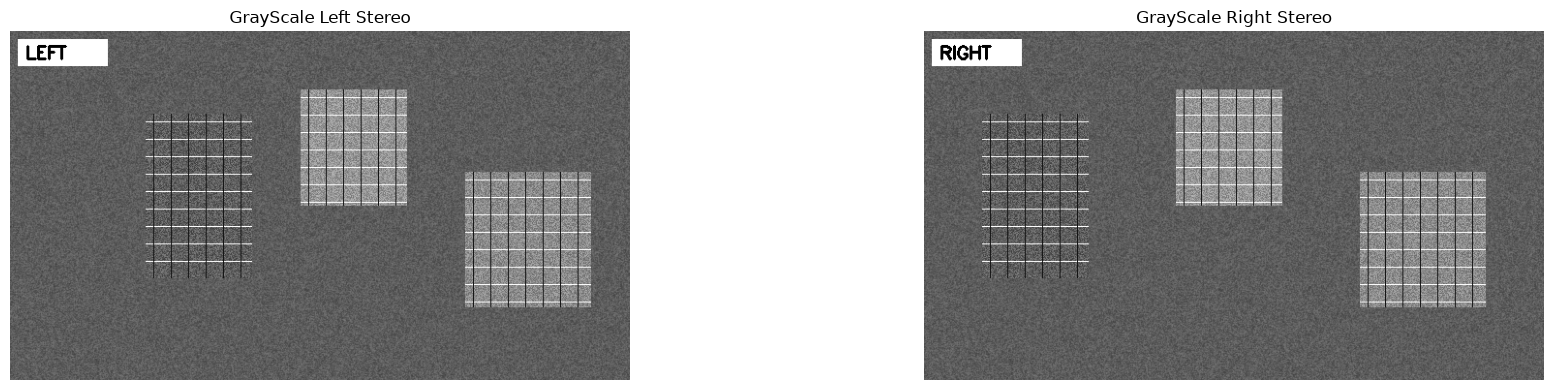

In [3]:
left_img_path = "stereo_left.png"
right_img_path = "stereo_right.png"

stereo_left = cv2.imread(left_img_path, cv2.IMREAD_GRAYSCALE)
stereo_right = cv2.imread(right_img_path, cv2.IMREAD_GRAYSCALE)

fig, axes = plt.subplots(1, 2, figsize=(20, 4))

axes[0].imshow(stereo_left, cmap="gray")
axes[0].set_title("GrayScale Left Stereo")
axes[0].axis("off")

axes[1].imshow(stereo_right, cmap="gray")
axes[1].set_title("GrayScale Right Stereo")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [4]:
sift = cv2.SIFT_create()

kp_left, des_left = sift.detectAndCompute(stereo_left, None)
kp_right, des_right = sift.detectAndCompute(stereo_right, None)

bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.knnMatch(des_left, des_right, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

near_points = []
mid_points = []
far_points = []

for m in good_matches:
    pt_l = kp_left[m.queryIdx].pt
    pt_r = kp_right[m.trainIdx].pt

    dx = pt_l[0] - pt_r[0]
    dy = pt_l[1] - pt_r[1]

    if not( abs(dy) <= 2.0 and dx > 0):
        continue

    Z = (focal_length * baseline) / dx
    
    if 65 <= dx <= 95:     # Near (~80 px)
        near_points.append((pt_l, dx, Z))
    elif 30 <= dx <= 50:   # Middle (~40 px)
        mid_points.append((pt_l, dx, Z))
    elif 12 <= dx <= 28:   # Far (~20 px)
        far_points.append((pt_l, dx, Z))

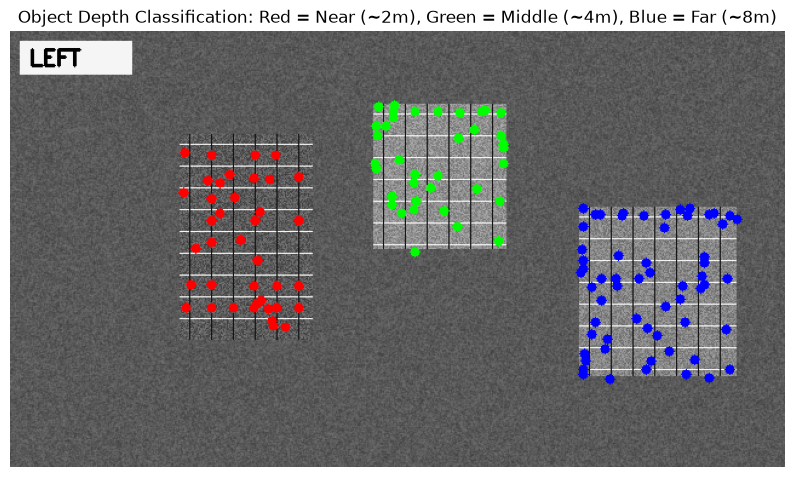

In [5]:
# Overlay detected objects color-coded by depth
vis_img = cv2.cvtColor(stereo_left, cv2.COLOR_GRAY2BGR)

# Red for Near (~2m), Green for Middle (~4m), Blue for Far (~8m)
for pt, _, _ in near_points:
    cv2.circle(vis_img, (int(pt[0]), int(pt[1])), 4, (0, 0, 255), -1)
for pt, _, _ in mid_points:
    cv2.circle(vis_img, (int(pt[0]), int(pt[1])), 4, (0, 255, 0), -1)
for pt, _, _ in far_points:
    cv2.circle(vis_img, (int(pt[0]), int(pt[1])), 4, (255, 0, 0), -1)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB))
plt.title("Object Depth Classification: Red = Near (~2m), Green = Middle (~4m), Blue = Far (~8m)")
plt.axis('off')
plt.show()

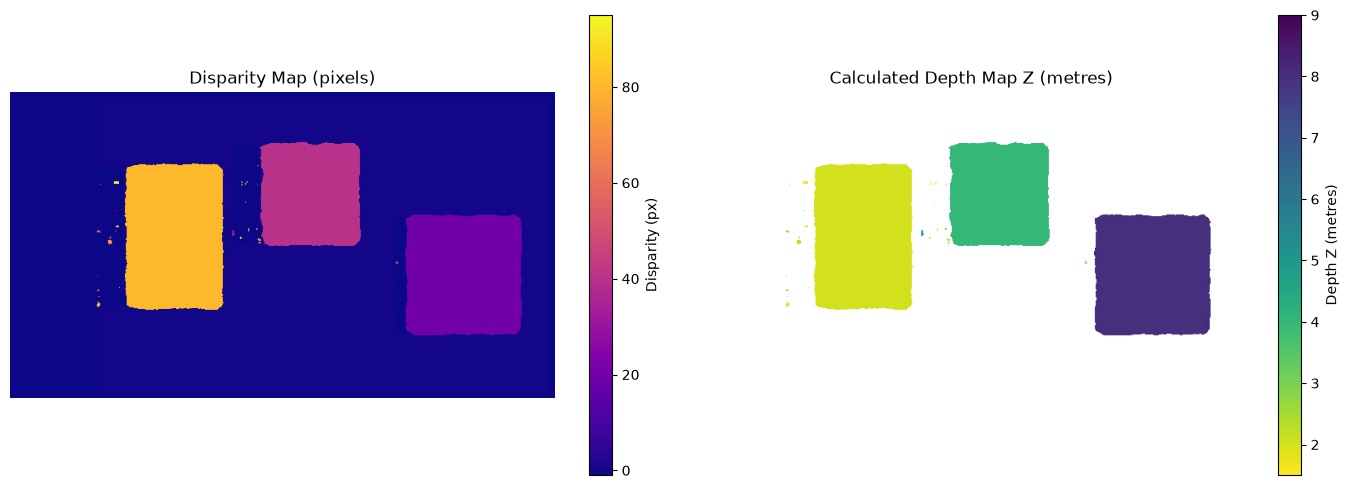

In [6]:
# Create Block Matching stereo solver
# Note: numDisparities must be divisible by 16
stereo = cv2.StereoBM_create(numDisparities=96, blockSize=15)

# Compute disparity (returns 16-bit fixed point, divide by 16 for true pixel values)
disparity = stereo.compute(stereo_left, stereo_right).astype(np.float32) / 16.0

depth_map = np.zeros_like(disparity)
valid_mask = disparity > 0
depth_map[valid_mask] = (focal_length * baseline) / disparity[valid_mask]

depth_map_display = np.copy(depth_map)
depth_map_display[~valid_mask] = np.nan

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(disparity, cmap='plasma')
plt.title("Disparity Map (pixels)")
plt.colorbar(label="Disparity (px)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(depth_map_display, cmap="viridis_r", vmin=1.5, vmax=9.0)
plt.title("Calculated Depth Map Z (metres)")
plt.colorbar(label="Depth Z (metres)")
plt.axis("off")

plt.tight_layout()
plt.show()

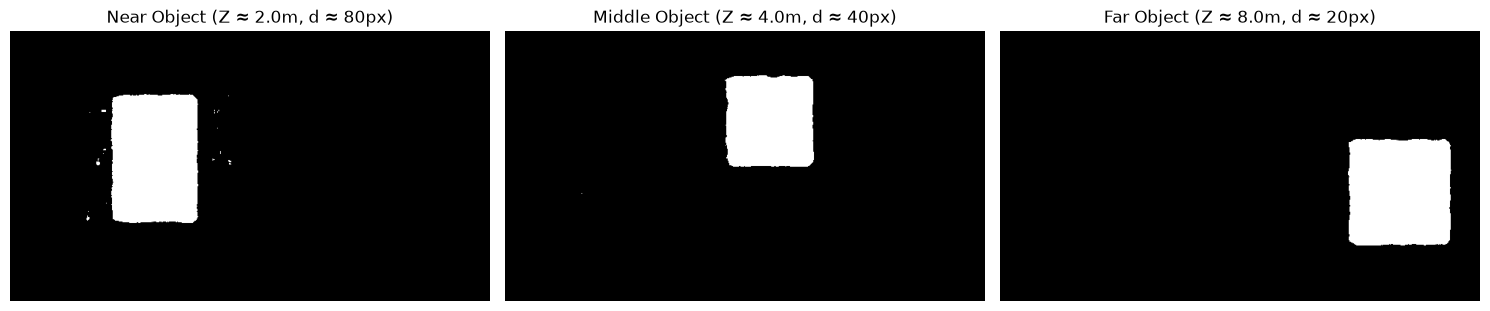

In [7]:
# Isolate masks for each object based on calculated depth
near_mask = (depth_map >= 1.5) & (depth_map <= 2.5)   # ~ 2.0 m
mid_mask  = (depth_map >= 3.5) & (depth_map <= 4.5)   # ~ 4.0 m
far_mask  = (depth_map >= 7.0) & (depth_map <= 9.0)   # ~ 8.0 m

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(near_mask, cmap='gray')
plt.title("Near Object (Z ≈ 2.0m, d ≈ 80px)")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mid_mask, cmap='gray')
plt.title("Middle Object (Z ≈ 4.0m, d ≈ 40px)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(far_mask, cmap='gray')
plt.title("Far Object (Z ≈ 8.0m, d ≈ 20px)")
plt.axis('off')

plt.tight_layout()
plt.show()

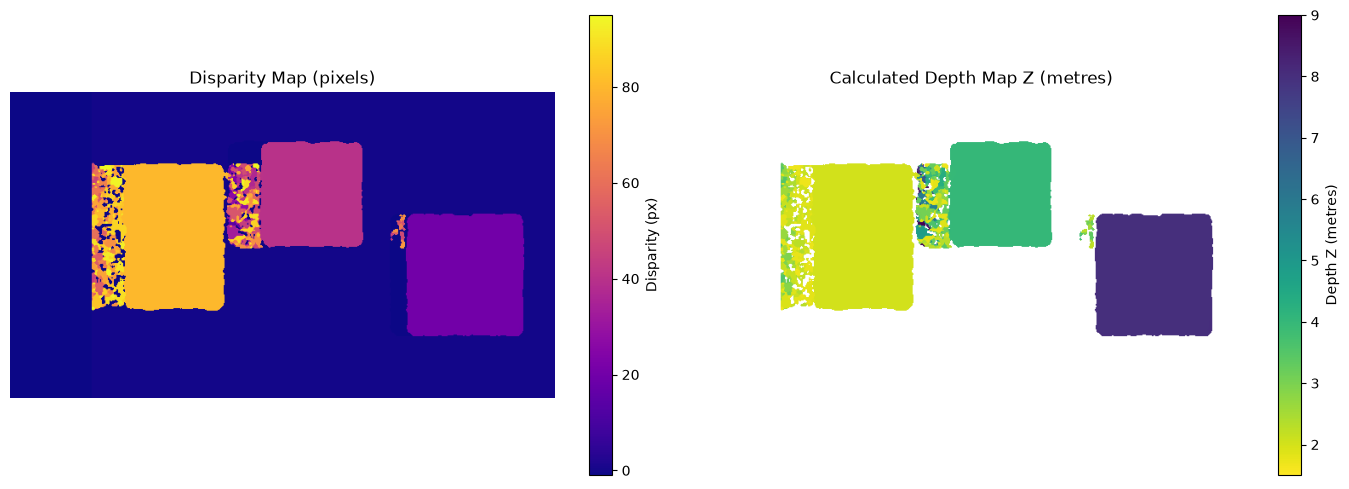

In [8]:
# Create Block Matching stereo solver
# Note: numDisparities must be divisible by 16
stereo = cv2.StereoSGBM_create(numDisparities=96, blockSize=15)

# Compute disparity (returns 16-bit fixed point, divide by 16 for true pixel values)
disparity = stereo.compute(stereo_left, stereo_right).astype(np.float32) / 16.0

depth_map = np.zeros_like(disparity)
valid_mask = disparity > 0
depth_map[valid_mask] = (focal_length * baseline) / disparity[valid_mask]

depth_map_display = np.copy(depth_map)
depth_map_display[~valid_mask] = np.nan

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(disparity, cmap='plasma')
plt.title("Disparity Map (pixels)")
plt.colorbar(label="Disparity (px)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(depth_map_display, cmap="viridis_r", vmin=1.5, vmax=9.0)
plt.title("Calculated Depth Map Z (metres)")
plt.colorbar(label="Depth Z (metres)")
plt.axis("off")

plt.tight_layout()
plt.show()

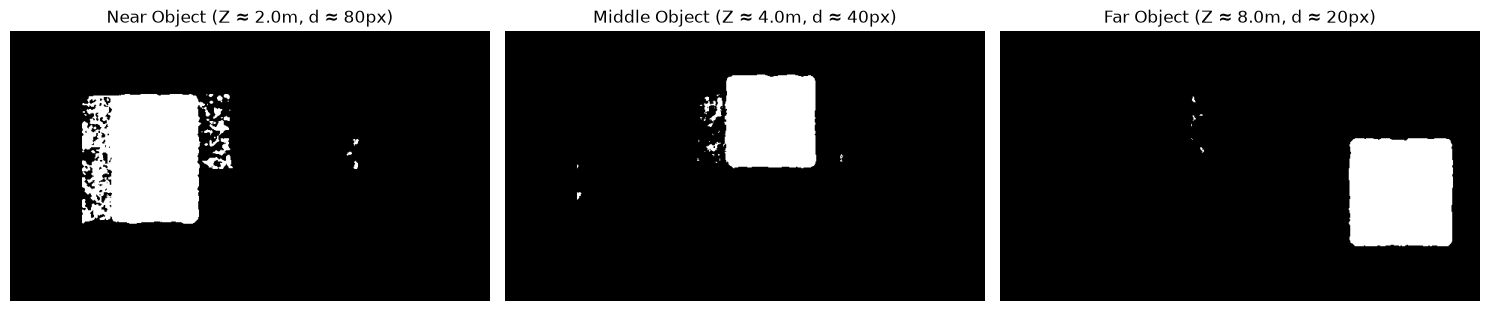

In [9]:
# Isolate masks for each object based on calculated depth
near_mask = (depth_map >= 1.5) & (depth_map <= 2.5)   # ~ 2.0 m
mid_mask  = (depth_map >= 3.5) & (depth_map <= 4.5)   # ~ 4.0 m
far_mask  = (depth_map >= 7.0) & (depth_map <= 9.0)   # ~ 8.0 m

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(near_mask, cmap='gray')
plt.title("Near Object (Z ≈ 2.0m, d ≈ 80px)")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mid_mask, cmap='gray')
plt.title("Middle Object (Z ≈ 4.0m, d ≈ 40px)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(far_mask, cmap='gray')
plt.title("Far Object (Z ≈ 8.0m, d ≈ 20px)")
plt.axis('off')

plt.tight_layout()
plt.show()

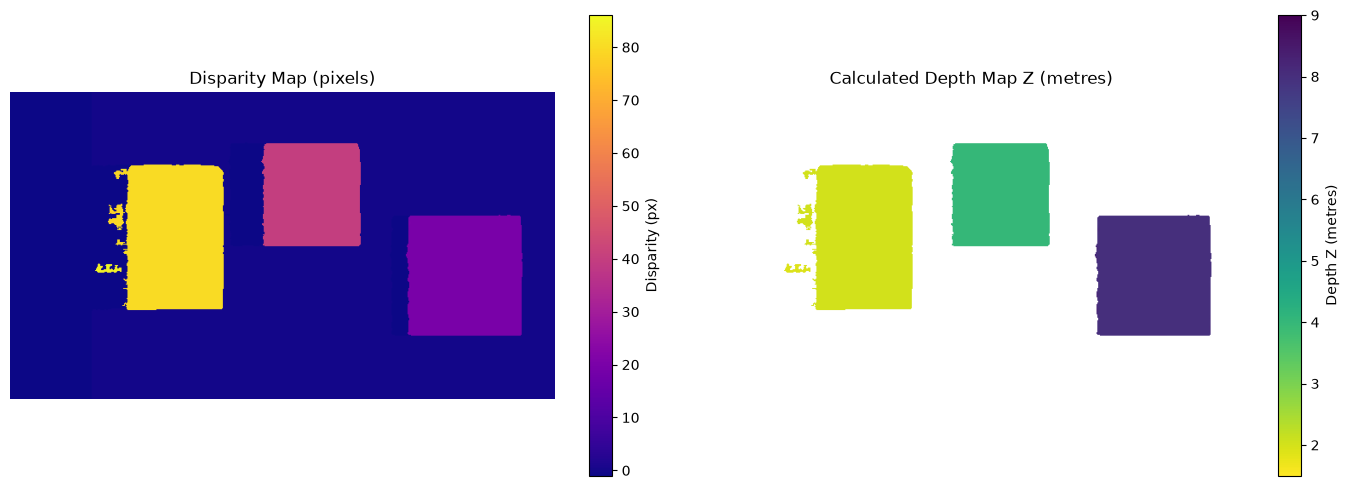

In [10]:
# Create Block Matching stereo solver
# Note: numDisparities must be divisible by 16
stereo = cv2.StereoSGBM_create(
    minDisparity=0, numDisparities=96, blockSize=5,
    P1=8 * 1 * 5**2, P2=32 * 1 * 5**2,
    disp12MaxDiff=1, uniquenessRatio=15,
    speckleWindowSize=150, speckleRange=2,
    mode = cv2.STEREO_SGBM_MODE_SGBM_3WAY
    )

# Compute disparity (returns 16-bit fixed point, divide by 16 for true pixel values)
disparity = stereo.compute(stereo_left, stereo_right).astype(np.float32) / 16.0

depth_map = np.zeros_like(disparity)
valid_mask = disparity > 0
depth_map[valid_mask] = (focal_length * baseline) / disparity[valid_mask]

depth_map_display = np.copy(depth_map)
depth_map_display[~valid_mask] = np.nan

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(disparity, cmap='plasma')
plt.title("Disparity Map (pixels)")
plt.colorbar(label="Disparity (px)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(depth_map_display, cmap="viridis_r", vmin=1.5, vmax=9.0)
plt.title("Calculated Depth Map Z (metres)")
plt.colorbar(label="Depth Z (metres)")
plt.axis("off")

plt.tight_layout()
plt.show()

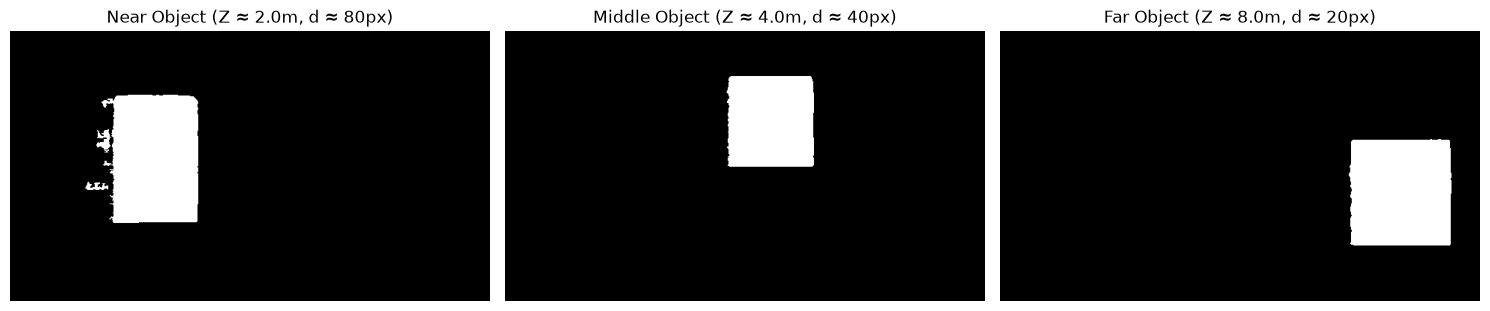

In [11]:
# Isolate masks for each object based on calculated depth
near_mask = (depth_map >= 1.5) & (depth_map <= 2.5)   # ~ 2.0 m
mid_mask  = (depth_map >= 3.5) & (depth_map <= 4.5)   # ~ 4.0 m
far_mask  = (depth_map >= 7.0) & (depth_map <= 9.0)   # ~ 8.0 m

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(near_mask, cmap='gray')
plt.title("Near Object (Z ≈ 2.0m, d ≈ 80px)")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mid_mask, cmap='gray')
plt.title("Middle Object (Z ≈ 4.0m, d ≈ 40px)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(far_mask, cmap='gray')
plt.title("Far Object (Z ≈ 8.0m, d ≈ 20px)")
plt.axis('off')

plt.tight_layout()
plt.show()